In [ ]:
import pandas as pd
import matplotlib.pyplot as plt 

df = pd.read_csv("../data/processed/music_data_features.csv")
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (89741, 23)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,trend_score,artist_avg_trend_score,genre_avg_trend_score
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,...,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,66.54,57.18,45.19
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,...,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,44.72,44.56,45.19
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,...,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,50.14,50.14,45.19
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,...,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,49.11,45.34,45.19
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,...,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,70.42,44.14,45.19


In [2]:
top_songs = df.sort_values("trend_score", ascending=False)[
    ["track_name", "artists", "trend_score"]
].head(10)
top_songs

,track_name,artists,trend_score
19299,Super Freaky Girl,Nicki Minaj,92.02
57111,Me Porto Bonito,Bad Bunny;Chencho Corleone,90.66
18913,I'm Good (Blue),David Guetta;Bebe Rexha,89.32
57109,La Bachata,Manuel Turizo,89.08
57495,LOKERA,Rauw Alejandro;Lyanno;Brray,87.84
66009,I Ain't Worried,OneRepublic,87.62
45781,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,87.46
67655,Calm Down (with Selena Gomez),Rema;Selena Gomez,87.34
67815,Bad Habits,Ed Sheeran,86.80
57653,Party,Bad Bunny;Rauw Alejandro,86.56


In [3]:
top_artists = (
    df.groupby("artists")["trend_score"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
top_artists

artists
Bad Bunny;Chencho Corleone     90.66
Nicki Minaj                    89.20
Manuel Turizo                  89.08
Rauw Alejandro;Lyanno;Brray    87.84
Bizarrap;Quevedo               87.46
Rema;Selena Gomez              87.34
Bad Bunny;Rauw Alejandro       86.56
PSY;SUGA                       85.94
Beyoncé                        85.18
Imanbek;BYOR                   85.04
Name: trend_score, dtype: float64

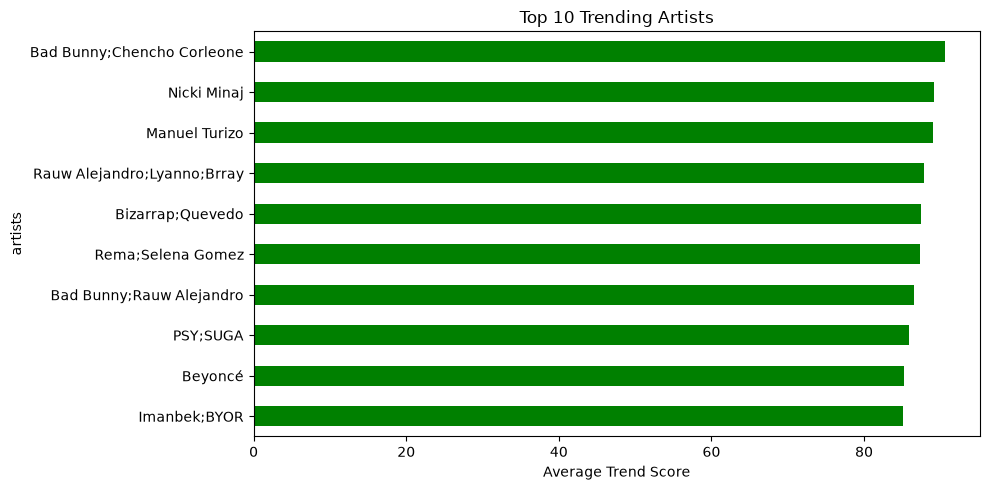

In [4]:
plt.figure(figsize=(10, 5))
top_artists.plot(kind="barh", color="green")
plt.xlabel("Average Trend Score")
plt.title("Top 10 Trending Artists")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [5]:
genre_trend = (
    df.groupby("track_genre")["trend_score"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
genre_trend

track_genre
k-pop                62.101592
latino               60.429975
metal                60.304828
pop-film             59.284712
reggaeton            58.577297
progressive-house    56.690834
deep-house           56.385988
grunge               55.557889
sertanejo            54.627506
emo                  54.477833
Name: trend_score, dtype: float64

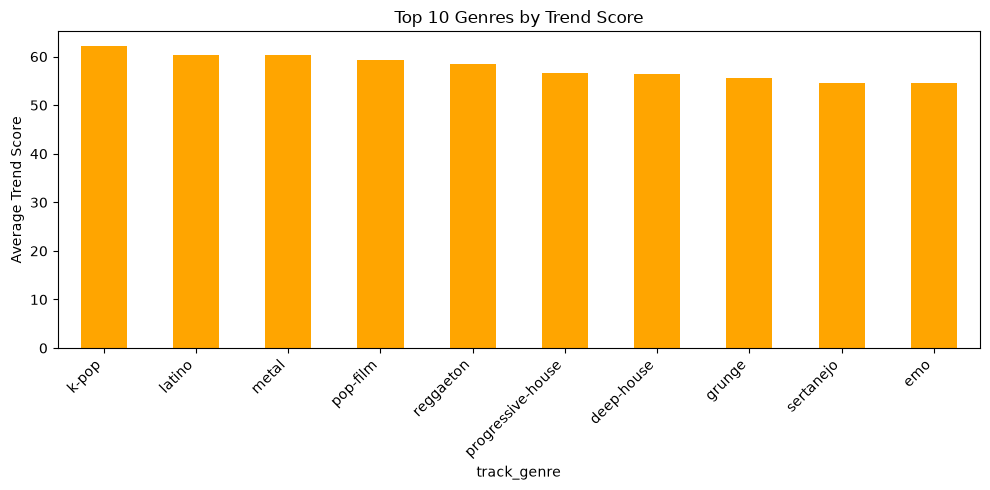

In [6]:
plt.figure(figsize=(10, 5))
genre_trend.plot(kind="bar", color="orange")
plt.ylabel("Average Trend Score")
plt.title("Top 10 Genres by Trend Score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()